 # 1) Problem Statement
~ This project understand how the students performance (test score) is affected by other variables such as gender, Ethnicity, parental level of education, Lunch and test preparation course.

# 2) Data Collection
~ Dataset Sources ~ https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

# Import csv Data as Pandas DataFrame

In [23]:
df=pd.read_csv("data/stud.csv")

In [24]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [25]:
df.shape

(1000, 8)

In [26]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

There is no missing value in the dataset

In [27]:
df.duplicated().sum()

np.int64(0)

No duplicate values in this dataset

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [29]:
# Check the number of unique value of each columns
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [30]:
# describe statistics of dataset
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


Insights  

    . From above description of numerical data , all means are very close to dataset(between 66-68).  

    . All standard deviation are also close(14.6-15.19).  

    . where there is a minimum score 0 for math_score, for writing minimum is much higher = 10 and for reading might higher = 17.


In [32]:
# Exploring Data
print("Categories in 'gender' variable:   ",end='')
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:   ",end="")
print(df['race_ethnicity'].unique())

print("Categories in 'parental_level_of_education' variable:   ",end="")
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:   ",end='')
print(df['lunch'].unique())

print("Categories in 'test_preparation_course' variable:   ",end='')
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:   <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:   <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental_level_of_education' variable:   <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:   <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test_preparation_course' variable:   <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [33]:
# Define numerical and categorical feature
numerical_feature = [feature for feature in df.columns if df[feature].dtype != 'str']
categorical_feature = [feature for feature in df.columns if df[feature].dtype == 'str']


print(f"{len(numerical_feature)} Numerical Features: {numerical_feature} ")
print(f"{len(categorical_feature)} Categorical Features:  {categorical_feature} ")

3 Numerical Features: ['math_score', 'reading_score', 'writing_score'] 
5 Categorical Features:  ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course'] 


In [34]:
# Adding columns for 'total score' and 'Average'
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']

df['average_score'] = df['total_score'] / 3
df.head()



,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [37]:
reading_full = df[df['reading_score'] == 100]['average_score'].count()
writing_full = df[df['writing_score']==100]['average_score'].count()
math_full = df[df['math_score']==100]['average_score'].count()

print(f"Number of students with full marks in Math: {math_full}")
print(f"Number of students with full marks in Reading: {reading_full}")
print(f"Number of students with full marks in Writing: {writing_full}")

Number of students with full marks in Math: 7
Number of students with full marks in Reading: 17
Number of students with full marks in Writing: 14


In [38]:
reading_less_20=df[df['reading_score'] <= 20]['average_score'].count()
writing_less_20=df[df['writing_score'] <= 20]['average_score'].count()
math_less_20=df[df['math_score'] <= 20]['average_score'].count()

print(f"Number of students with less than 20 marks in Math: {math_less_20}")
print(f"Number of students with less than 20 marks in Reading: {reading_less_20}")
print(f"Number of students with less than 20 marks in Writing: {writing_less_20}")

Number of students with less than 20 marks in Math: 4
Number of students with less than 20 marks in Reading: 1
Number of students with less than 20 marks in Writing: 3


Insights  
    
    ~ From above value we can say that students are worst performed in Math Section.  
    
    ~ Best Performed in Reading section.

# Exploring Data (Visualization )

Visualize Average score of distribution to make some conclusion.  
> Histogram  
> Kernal Distribution Function(KDE)


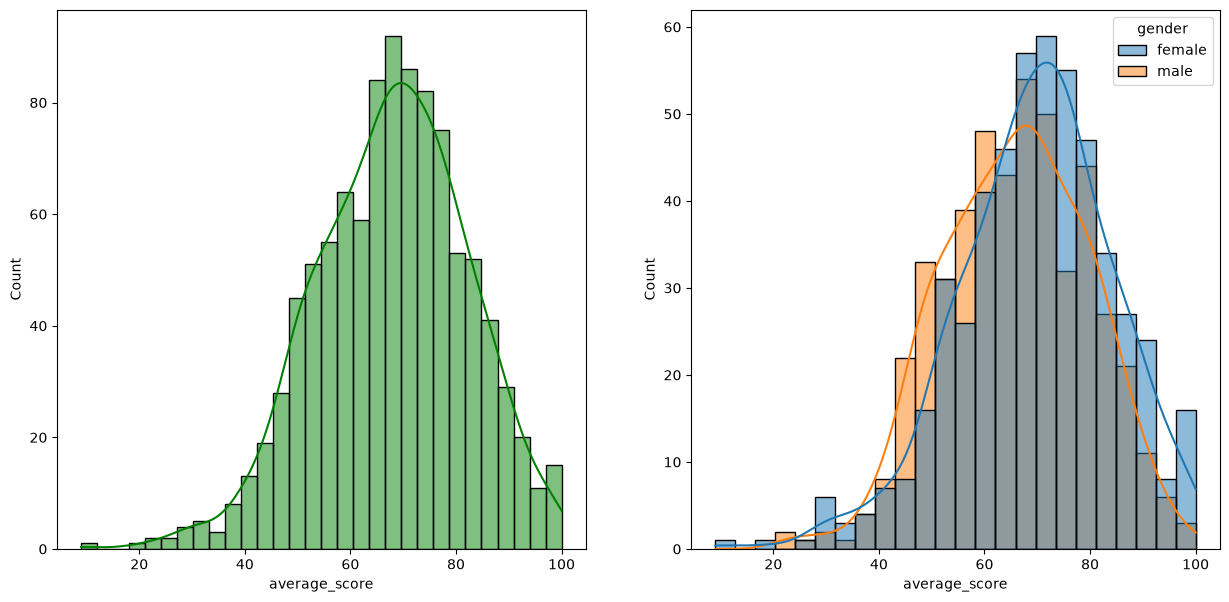

In [42]:
# Histogram and kde
fig,axs=plt.subplots(1,2, figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='average_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average_score',hue='gender',kde=True)
plt.show()

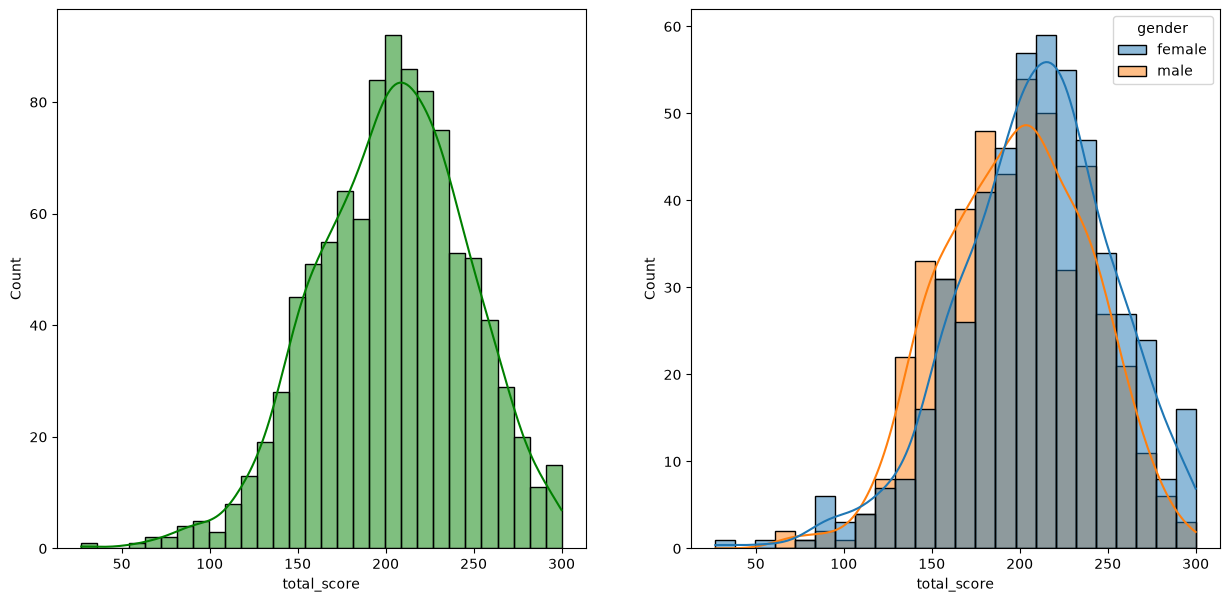

In [43]:
# Histogram and kde
fig,axs=plt.subplots(1,2, figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',hue='gender',kde=True)
plt.show()

Insights  
    ~ Female students are performing well compare to male student.

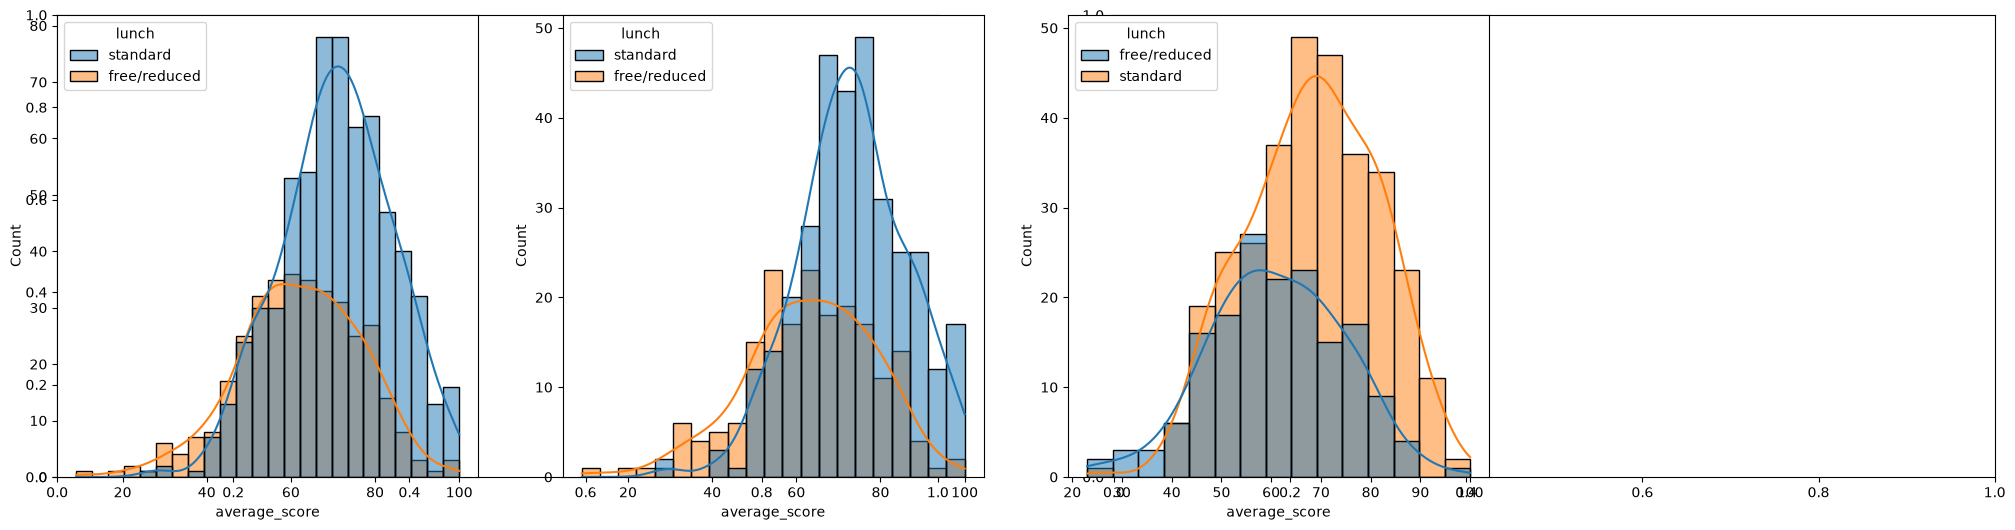

In [52]:
# Histogram and kde
fig,axs=plt.subplots(1,2, figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x='average_score',kde=True,hue='lunch')
plt.subplot(142)
sns.histplot(x='average_score',data=df[df.gender=='female'],kde=True,hue='lunch')
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x='average_score',hue='lunch',kde=True)
plt.show()